# Example: Stress-Testing a Strategy with the Five Gates
In this example, we stress-test one strategy from [the strategy menu](strategies/CHEME-5660-L15a-Strategy-Menu-Fall-2026.ipynb) on 200 synthetic markets.

Each market is the real history to November 24, 2026, followed by one synthetic year of 252 trading days. We plot the range of the strategy's wealth, test the strategy with the five gates, and then test it again with the market hedge on.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Plot the range of outcomes:__ Plot the percentiles of the strategy's wealth over the 200 synthetic markets, and compare them with those of the same investment in `SPY`.
> * __Test a strategy with the five gates:__ Compute the five gates of the strategy, and test each gate against its limit.
> * __Turn the market hedge on:__ Test the same strategy with the market hedge on, and compare its gates with those of the strategy without the hedge.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, and loads the functions in the local `src` directory. It also loads the strategy files in the `strategies` folder and [the strategy menu](strategies/menu.jl).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
The stress test ran every strategy on the menu on the 200 synthetic markets. With 5 seeds for each random picking rule, the menu has 756 stress tests. We load the saved results with [the `JLD2.load(...)` function](https://juliaio.github.io/JLD2.jl/stable/basic_usage/#FileIO-interface).

Market `p` uses the seed `5660 + p`, the seed of the practicum's stress test. On each market, a strategy makes its first decision after the close of November 24, 2026, and trades for the 252 synthetic days.

We store the saved results in five variables:
* The `stress_runs::DataFrame` variable holds one row per strategy and market. Each row holds the strategy's choices, the market's number in the `path_id` column, and the strategy's scores on that market, for example its Sharpe ratio, its largest drawdown, its wealth on the last day, and its net present value (NPV).
* The `synthetic_dates::Vector{Date}` variable holds November 24, 2026, and then the 252 synthetic trading days. The `spy_closes::Matrix{Float64}` and `tlt_closes::Matrix{Float64}` variables hold the closing prices of `SPY` and of the long-term Treasury bond fund `TLT` on these days (days × markets, USD/share).
* The `wealth_bands::Dict{String, Matrix{Float32}}` variable holds, for each strategy, the 5th, 25th, 50th, 75th, and 95th percentiles of its wealth on each day over the markets (days × percentiles, USD).

In [2]:
stress_runs, synthetic_dates, spy_closes, tlt_closes, wealth_bands = let

    # load the saved stress test of every strategy on the menu -
    saved = JLD2.load(joinpath(_PATH_TO_DATA, "L15a-Strategies-Synthetic.jld2"));
    stress_runs = saved["summary"];
    synthetic_dates = saved["dates"];
    spy_closes = Float64.(saved["spy"]);
    tlt_closes = Float64.(saved["tlt"]);
    wealth_bands = saved["bands"];

    # checks -
    @assert synthetic_dates[1] == Date(2026, 11, 24) && length(synthetic_dates) == 253 "the markets must start on 2026-11-24 and run 252 synthetic days"
    @assert size(spy_closes) == (253, 200) && size(tlt_closes) == (253, 200) "one close per day and market"
    @assert all(stress_runs.status .== "ok") "every saved run must have run without an error"

    # return -
    stress_runs, synthetic_dates, spy_closes, tlt_closes, wealth_bands
end;
println("$(nrow(stress_runs)) saved runs on $(maximum(stress_runs.path_id)) markets, $(synthetic_dates[2]) to $(synthetic_dates[end])");

151200 saved runs on 200 markets, 2026-11-25 to 2027-11-26


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. The names on the menu are listed in [the strategy menu](strategies/CHEME-5660-L15a-Strategy-Menu-Fall-2026.ipynb):

In [3]:
my_picking = "gamma by sector"; # the picking rule: a name on the picking menu, for example "liquid gamma"
my_weighting = "Cobb-Douglas"; # the weighting rule: a name on the weighting menu, for example "equal weight"
my_estimates = "fixed"; # "fixed" keeps the 2016 to 2024 estimates, and "updated" updates them on each trading day
my_seed = 5660; # seed of the strategy's random draws: 5660, or 1 to 5 with a random picking rule (the saved seeds)
W0 = 100000.0; # starting wealth of the saved runs (USD), which must stay 100000.0 to match them
sharpe_limit = 0.3; # gate 1: the smallest median Sharpe ratio that passes (dimensionless)
drawdown_limit = 0.25; # gate 2: the largest median drawdown that passes (fraction of the peak wealth)
failure_limit = 0.10; # gate 3: the largest share of markets ending below W0 that passes
half_spread = 0.0005; # half bid-ask spread of each trade of the 60/40 benchmark (fraction of the trade's value)

___

## Task 1: Plot the Range of Outcomes
In this task, we plot the range of the strategy's wealth over the 200 synthetic markets, and compare it with the same investment in `SPY`.

We compute the same percentiles for `SPY` with [the `quantile(...)` function](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.quantile). We store the percentiles of the strategy, which pool the 5 seeds of a random picking rule, in the `strategy_band::Matrix{Float64}` variable and those of `SPY` in the `spy_band::Matrix{Float64}` variable (days × percentiles, USD):

In [4]:
strategy_band, spy_band = let

    # the name of our strategy in the saved results -
    hedge_name = "hedge off"; # Tasks 1 and 2 run without the market hedge
    combination = my_picking * " | " * my_weighting * " | " * hedge_name * " | " * my_estimates;

    # the strategy's percentiles, saved by the stress test (USD) -
    strategy_band = Float64.(wealth_bands[combination]);

    # the wealth of USD W0 invested in SPY on each day and market, and its percentiles on each day (USD) -
    number_of_days = size(spy_closes, 1);
    number_of_markets = size(spy_closes, 2);
    percentiles = [0.05, 0.25, 0.50, 0.75, 0.95];
    spy_band = zeros(number_of_days, length(percentiles));
    for d ∈ 1:number_of_days
        W_spy = zeros(number_of_markets); # the wealth in SPY on day d of each market (USD)
        for p ∈ 1:number_of_markets
            W_spy[p] = W0 * spy_closes[d, p] / spy_closes[1, p];
        end
        for k ∈ 1:length(percentiles)
            spy_band[d, k] = quantile(W_spy, percentiles[k]);
        end
    end

    # checks -
    @assert size(strategy_band) == size(spy_band) "one percentile band per day for the strategy and for SPY"
    @assert strategy_band[1, 3] == W0 "the strategy starts with W0 on every market"

    # return -
    strategy_band, spy_band
end;

Let's plot the two bands with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot). The red areas and line show the strategy, and the gray lines show `SPY`. How do the two bands change over the year?

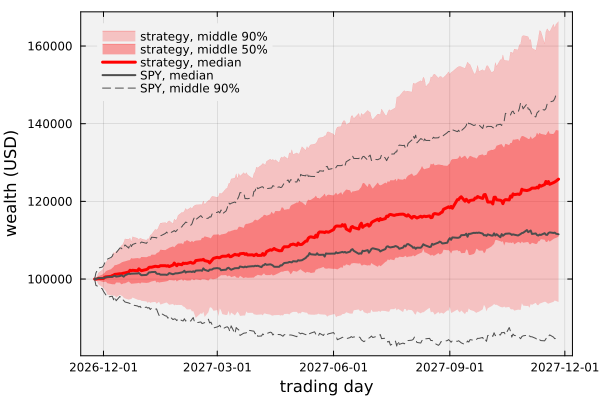

In [5]:
let

    # initialize: the synthetic days -
    days = synthetic_dates;

    # display options used in this cell -
    # fillrange: Shade the area between this series and the given lower series.
    # fillalpha: Set the opacity of the shaded area, from 0 (clear) to 1 (solid).
    # lw: Set the line width in points; 0 draws no line.
    # ls: Set the line style, for example :dash.
    # c: Choose the series color.
    # label: Set the legend entry.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legend: Set where the legend goes.
    # yformatter: Write the axis numbers in full, without scientific notation.
    # right_margin: Leave room on the right for the last date label.
    p = plot(days, strategy_band[:, 5], fillrange = strategy_band[:, 1], fillalpha = 0.2, lw = 0, c = :red,
        label = "strategy, middle 90%", bg = "gray95", background_color_outside = "white", framestyle = :box,
        fg_legend = :transparent, legend = :topleft, yformatter = :plain, right_margin = 5Plots.mm);
    plot!(p, days, strategy_band[:, 4], fillrange = strategy_band[:, 2], fillalpha = 0.35, lw = 0, c = :red,
        label = "strategy, middle 50%");
    plot!(p, days, strategy_band[:, 3], lw = 3, c = :red, label = "strategy, median");
    plot!(p, days, spy_band[:, 3], lw = 2, c = :gray30, label = "SPY, median");
    plot!(p, days, spy_band[:, 1], lw = 1, ls = :dash, c = :gray30, label = "SPY, middle 90%");
    plot!(p, days, spy_band[:, 5], lw = 1, ls = :dash, c = :gray30, label = "");
    xlabel!(p, "trading day");
    ylabel!(p, "wealth (USD)");

    # return -
    p
end

> __What do we see?__ The bands of the strategy and of `SPY` widen over the year. On the last day, `SPY` ends below `W0` on 49 of the 200 markets.

___

## Task 2: Test the Strategy with the Five Gates
In this task, we test the strategy with the five gates of the stress test.

The constants `sharpe_limit`, `drawdown_limit`, and `failure_limit` hold the practicum's limits of the first three gates. In the fourth gate, a strategy with fixed estimates faces the 60/40 benchmark, and a strategy with updated estimates faces its copy with fixed estimates.

First, we find the 200 runs of our strategy with [the `find_runs(...)` function](src/Helper.jl), and the comparison's wealth on the last day of each market. [The `sixty_forty_wealth(...)` function](src/Helper.jl) computes the wealth of the 60/40 benchmark, starting in cash on the first synthetic day. We store our runs in the `our_runs::DataFrame` variable and the comparison's wealth in the `comparison_terminal::Vector{Float64}` variable (USD):

In [6]:
our_runs, comparison_terminal = let

    # our strategy's run on each market, in market order -
    our_runs = find_runs(stress_runs; picking = my_picking, weighting = my_weighting, hedge = false,
        estimates = my_estimates, seed = my_seed);

    # the comparison's wealth on the last day of each market (USD) -
    number_of_markets = nrow(our_runs);
    comparison_terminal = zeros(number_of_markets);
    if my_estimates == "fixed"
        # the 60/40 benchmark, from the first synthetic day to the last -
        for k ∈ 1:number_of_markets
            p = our_runs.path_id[k];
            W_6040 = sixty_forty_wealth(spy_closes[2:end, p], tlt_closes[2:end, p], synthetic_dates[2:end];
                W0 = W0, half_spread = half_spread);
            comparison_terminal[k] = W_6040[end];
        end
    else
        # the same strategy with fixed estimates, on the same markets -
        fixed_runs = find_runs(stress_runs; picking = my_picking, weighting = my_weighting, hedge = false,
            estimates = "fixed", seed = my_seed);
        for k ∈ 1:nrow(fixed_runs)
            comparison_terminal[k] = fixed_runs.terminal[k];
        end
    end

    # checks -
    @assert number_of_markets == 200 "our strategy must have one saved run on each of the 200 markets"
    @assert all(comparison_terminal .> 0) "the comparison must have a wealth on every market"

    # return -
    our_runs, comparison_terminal
end;

Let's plot the strategy's wealth on the last day of each market with [the `histogram(...)` function](https://docs.juliaplots.org/stable/api/#Plots.histogram). The black line marks `W0`, and the bars to its left are the failures. The blue line marks the comparison's median:

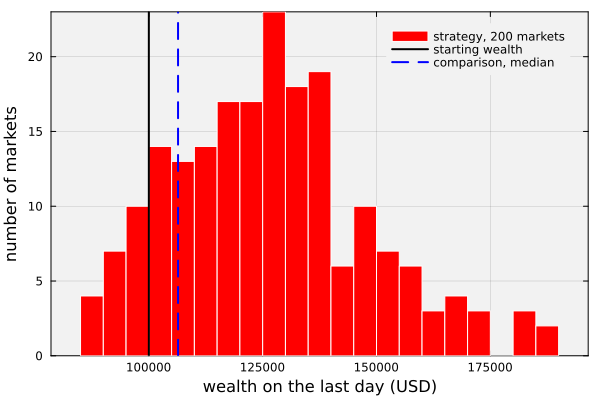

In [7]:
let

    # display options used in this cell (see Task 1 for the others) -
    # bins: Set the number of bars.
    # lc: Set the color of the bar outlines.
    p = histogram(our_runs.terminal, bins = 30, c = :red, lc = :white, label = "strategy, 200 markets", bg = "gray95",
        background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legend = :topright,
        xformatter = :plain);
    vline!(p, [W0], lw = 2, c = :black, label = "starting wealth");
    vline!(p, [median(comparison_terminal)], lw = 2, ls = :dash, c = :blue, label = "comparison, median");
    xlabel!(p, "wealth on the last day (USD)");
    ylabel!(p, "number of markets");

    # return -
    p
end

Finally, let's test the strategy with the five gates. [The `five_gates(...)` function](src/Helper.jl) computes each gate's value and limit as the practicum does, and [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table) displays them. We store the table in the `gates_off::DataFrame` variable:

In [8]:
gates_off = let

    # the five gates of our strategy -
    gates = five_gates(our_runs, comparison_terminal; W0 = W0, sharpe_limit = sharpe_limit,
        drawdown_limit = drawdown_limit, failure_limit = failure_limit);

    # let's display the gates in a table -
    pretty_table(gates;
        column_labels = ["gate", "value", "limit", "passed"], # displayed column headings
        alignment = [:l, :r, :r, :c], # :l aligns a column left, :r right, and :c in the center
        formatters = [fmt__printf("%.3f", [2, 3])], # three decimals
        table_format = TextTableFormat(borders = text_table_borders__compact), # compact separator characters
        fit_table_in_display_horizontally = false, # keep all columns
        fit_table_in_display_vertically = false # keep all rows
    );

    # return -
    gates
end;

 ------------------------------------- ------------ ------------ --------
  gate                                       value        limit   passed 
 ------------------------------------- ------------ ------------ --------
  median Sharpe ratio                        1.100        0.300    true
  median largest drawdown                    0.113        0.250    true
  failure rate                               0.105        0.100   false
  median wealth on the last day (USD)   125722.946   106414.434    true
  median NPV (USD)                       20576.046        0.000    true
 ------------------------------------- ------------ ------------ --------


> __What do we see?__ With the practicum's settings, only 23 of the 756 stress tests of the menu pass all five gates. Every other stress test fails the failure-rate gate. The 60/40 benchmark would fail that gate too, because it ends below `W0` on 56 of the 200 markets.

___

## Task 3: Turn the Market Hedge On
In this task, we test the same strategy with the market hedge on, and change nothing else.

The comparison of the fourth gate stays the same, except that the copy with fixed estimates also has the hedge on.

We store the hedged runs in the `hedged_runs::DataFrame` variable and their comparison in the `hedged_comparison::Vector{Float64}` variable (USD):

In [9]:
hedged_runs, hedged_comparison = let

    # our strategy with the hedge on, on each market, in market order -
    hedged_runs = find_runs(stress_runs; picking = my_picking, weighting = my_weighting, hedge = true,
        estimates = my_estimates, seed = my_seed);

    # the comparison: the same 60/40 benchmark, or the hedged copy with fixed estimates (USD) -
    number_of_markets = nrow(hedged_runs);
    hedged_comparison = zeros(number_of_markets);
    if my_estimates == "fixed"
        hedged_comparison = copy(comparison_terminal);
    else
        hedged_fixed_runs = find_runs(stress_runs; picking = my_picking, weighting = my_weighting, hedge = true,
            estimates = "fixed", seed = my_seed);
        for k ∈ 1:nrow(hedged_fixed_runs)
            hedged_comparison[k] = hedged_fixed_runs.terminal[k];
        end
    end

    # checks -
    @assert number_of_markets == 200 "the hedged strategy must have one saved run on each of the 200 markets"
    @assert hedged_runs.path_id == our_runs.path_id "both strategies must list the markets in the same order"

    # return -
    hedged_runs, hedged_comparison
end;

Let's plot each market's wealth on the last day with the hedge on against the wealth with the hedge off, with the [`scatter(...)` function](https://docs.juliaplots.org/stable/api/#Plots.scatter). A point above the diagonal line is a market on which the hedge ended with more wealth:

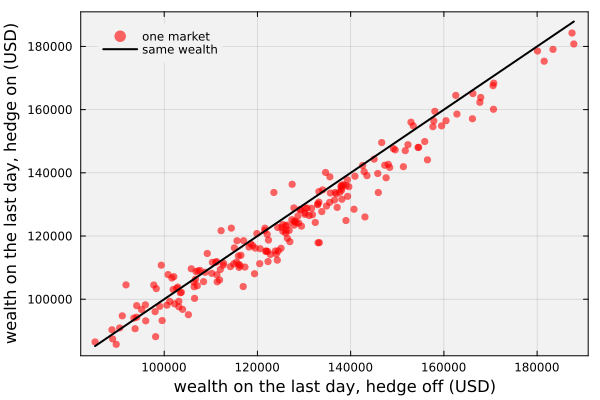

In [10]:
let

    # the range of both axes, so the diagonal line spans the points (USD) -
    lowest = min(minimum(our_runs.terminal), minimum(hedged_runs.terminal));
    highest = max(maximum(our_runs.terminal), maximum(hedged_runs.terminal));

    # display options used in this cell (see Task 1 for the others) -
    # ms: Set the marker size in points.
    # msw: Set the marker outline width in points.
    # ma: Set the marker opacity, from 0 (clear) to 1 (solid).
    p = scatter(our_runs.terminal, hedged_runs.terminal, ms = 4, msw = 0, c = :red, ma = 0.6, label = "one market",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
        legend = :topleft, xformatter = :plain, yformatter = :plain);
    plot!(p, [lowest, highest], [lowest, highest], lw = 2, c = :black, label = "same wealth");
    xlabel!(p, "wealth on the last day, hedge off (USD)");
    ylabel!(p, "wealth on the last day, hedge on (USD)");

    # return -
    p
end

Finally, let's compute the five gates with the hedge on, and display them next to the gates without the hedge:

In [11]:
let

    # the five gates of the hedged strategy -
    gates_on = five_gates(hedged_runs, hedged_comparison; W0 = W0, sharpe_limit = sharpe_limit,
        drawdown_limit = drawdown_limit, failure_limit = failure_limit);

    # one row per gate: the value, limit, and result without and with the hedge -
    df = DataFrame(gate = gates_off.gate, value_off = gates_off.value, limit_off = gates_off.limit,
        passed_off = gates_off.passed, value_on = gates_on.value, limit_on = gates_on.limit, passed_on = gates_on.passed);

    # let's display the gates in a table -
    pretty_table(df;
        column_labels = ["gate", "hedge off", "limit", "passed", "hedge on", "limit", "passed"], # column headings
        alignment = [:l, :r, :r, :c, :r, :r, :c], # :l aligns a column left, :r right, and :c in the center
        formatters = [fmt__printf("%.3f", [2, 3, 5, 6])], # three decimals
        table_format = TextTableFormat(borders = text_table_borders__compact), # compact separator characters
        fit_table_in_display_horizontally = false, # keep all columns
        fit_table_in_display_vertically = false # keep all rows
    );
end

 ------------------------------------- ------------ ------------ -------- ------------ ------------ --------
  gate                                   hedge off        limit   passed     hedge on        limit   passed 
 ------------------------------------- ------------ ------------ -------- ------------ ------------ --------
  median Sharpe ratio                        1.100        0.300    true         0.953        0.300    true
  median largest drawdown                    0.113        0.250    true         0.106        0.250    true
  failure rate                               0.105        0.100   false         0.120        0.100   false
  median wealth on the last day (USD)   125722.946   106414.434    true    121740.272   106414.434    true
  median NPV (USD)                       20576.046        0.000    true     16756.417        0.000    true
 ------------------------------------- ------------ ------------ -------- ------------ ------------ --------


> __What do we see?__ Across the menu, the hedged run ends with more wealth in only 30,864 of the 75,600 pairs of runs that differ only in the hedge. The hedged run has the smaller drawdown in 41,852 pairs.

___

## Summary
In this example, we stress-tested one strategy from the menu on 200 synthetic markets, tested it with the five gates, and tested it again with the market hedge on.

> __Key Takeaways:__
>
> * __A stress test shows a range of outcomes:__ We ran the strategy on 200 synthetic markets that share the real history and differ in the next year. The percentiles of its wealth showed how far the outcome can spread. Even `SPY` ended below the starting wealth on 49 of the 200 markets.
> * __Most strategies fail the failure-rate gate:__ We tested the strategy's median outcome and its share of losing markets against the five gates. With the practicum's settings, only 23 of the 756 stress tests passed all five, and every other stress test failed the failure-rate gate.
> * __The hedge lowers the drawdown more often than it adds wealth:__ We ran the same strategy with the market hedge on. Across the menu, the hedged run had the smaller drawdown in 41,852 of the 75,600 pairs of runs that differ only in the hedge. It ended with more wealth in only 30,864 pairs.

Next time, we'll trade a strategy in a paper account at live market prices.

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___